In [3]:
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "raw"
OUTPUT_DIR = ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

APPLICATION_PATH = DATA_DIR / "application_train.csv"
BUREAU_PATH = DATA_DIR / "bureau.csv"

assert APPLICATION_PATH.exists(), "Missing application_train.csv"
assert BUREAU_PATH.exists(), "Missing bureau.csv"

con = duckdb.connect()

# Safely quote local file paths for SQL
def sql_path(path):
    return "'" + str(path).replace("'", "''") + "'"

con.execute(f"""
    CREATE OR REPLACE VIEW applications AS
    SELECT *
    FROM read_csv_auto({sql_path(APPLICATION_PATH)});
""")

con.execute(f"""
    CREATE OR REPLACE VIEW bureau AS
    SELECT *
    FROM read_csv_auto({sql_path(BUREAU_PATH)});
""")

print("Applications:", con.execute(
    "SELECT COUNT(*) FROM applications"
).fetchone()[0])

print("Bureau records:", con.execute(
    "SELECT COUNT(*) FROM bureau"
).fetchone()[0])

Applications: 307511
Bureau records: 1716428


In [5]:
display(con.execute("""
    SELECT
        COUNT(*) AS total_records,
        COUNT(DISTINCT SK_ID_CURR) AS unique_applicants,
        COUNT(DISTINCT SK_ID_BUREAU) AS unique_credit_accounts
    FROM bureau
""").df())

display(con.execute("""
    SELECT *
    FROM bureau
    LIMIT 5
""").df())

,total_records,unique_applicants,unique_credit_accounts
0,1716428,305811,1716428


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN


In [6]:
SQL_PATH = ROOT / "sql" / "03_credit_history_features.sql"

sql_script = SQL_PATH.read_text()

con.execute(sql_script)

print("Feature views created successfully.")

display(con.sql("""
    SELECT
        SK_ID_CURR,
        TARGET,
        bureau_total_accounts,
        bureau_active_accounts,
        bureau_total_debt,
        bureau_max_days_overdue,
        bureau_debt_credit_ratio
    FROM modeling_features
    LIMIT 10
""").df())

Feature views created successfully.


,SK_ID_CURR,TARGET,bureau_total_accounts,bureau_active_accounts,bureau_total_debt,bureau_max_days_overdue,bureau_debt_credit_ratio
0,418380,1,9,5,784764.0,0,0.334978
1,291476,0,1,1,0.0,0,NaN
2,204888,0,2,1,0.0,0,0.000000
3,353372,0,7,1,9855.0,0,0.040140
4,175109,0,4,1,94522.5,0,0.135516
5,224271,0,8,1,0.0,0,0.000000
6,136358,0,1,1,680179.5,0,0.503837
7,115637,0,6,0,0.0,0,0.000000
8,189992,0,6,3,261.0,0,0.000310
9,258569,0,6,2,0.0,0,0.000000


In [7]:
validation = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT SK_ID_CURR) AS unique_applicants,
        COUNT(*) - COUNT(DISTINCT SK_ID_CURR)
            AS duplicate_applicants
    FROM modeling_features
""").df()

display(validation)

assert validation["total_rows"].iloc[0] == 307511
assert validation["duplicate_applicants"].iloc[0] == 0

print("PASS: One row per application.")

,total_rows,unique_applicants,duplicate_applicants
0,307511,307511,0


PASS: One row per application.


In [8]:
target_validation = con.execute("""
    SELECT
        TARGET,
        COUNT(*) AS applicants,
        ROUND(100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (), 2
        ) AS percentage
    FROM modeling_features
    GROUP BY TARGET
    ORDER BY TARGET
""").df()

display(target_validation)

,TARGET,applicants,percentage
0,0,282686,91.93
1,1,24825,8.07


In [9]:
coverage = con.execute("""
    SELECT
        has_bureau_history,
        COUNT(*) AS applicants,
        ROUND(100.0 * AVG(TARGET), 2)
            AS difficulty_rate_pct
    FROM modeling_features
    GROUP BY has_bureau_history
    ORDER BY has_bureau_history
""").df()

display(coverage)

,has_bureau_history,applicants,difficulty_rate_pct
0,0,44020,10.12
1,1,263491,7.73


In [10]:
feature_columns = [
    "bureau_total_accounts",
    "bureau_total_credit",
    "bureau_total_debt",
    "bureau_max_days_overdue",
    "bureau_debt_credit_ratio"
]

feature_data = con.sql("""
    SELECT *
    FROM modeling_features
""").df()

missing_summary = (
    feature_data[feature_columns]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(
    missing_summary.to_frame("missing_pct")
)

,missing_pct
bureau_debt_credit_ratio,17.026058
bureau_total_debt,16.708345
bureau_total_credit,14.315260
bureau_total_accounts,14.314935
bureau_max_days_overdue,14.314935


In [12]:
account_risk = con.sql("""
    SELECT
        CASE
            WHEN bureau_total_accounts IS NULL
                THEN 'No bureau records'
            WHEN bureau_total_accounts <= 2
                THEN '1-2 accounts'
            WHEN bureau_total_accounts <= 5
                THEN '3-5 accounts'
            WHEN bureau_total_accounts <= 10
                THEN '6-10 accounts'
            ELSE '11+ accounts'
        END AS account_group,

        COUNT(*) AS applicants,

        ROUND(
            100.0 * AVG(TARGET), 2
        ) AS difficulty_rate_pct

    FROM modeling_features
    GROUP BY account_group
    ORDER BY
        CASE account_group
            WHEN 'No bureau records' THEN 1
            WHEN '1-2 accounts' THEN 2
            WHEN '3-5 accounts' THEN 3
            WHEN '6-10 accounts' THEN 4
            ELSE 5
        END
""").df()

display(account_risk)

,account_group,applicants,difficulty_rate_pct
0,No bureau records,44020,10.12
1,1-2 accounts,71707,8.20
2,3-5 accounts,86883,7.40
3,6-10 accounts,72624,7.46
4,11+ accounts,32277,8.18


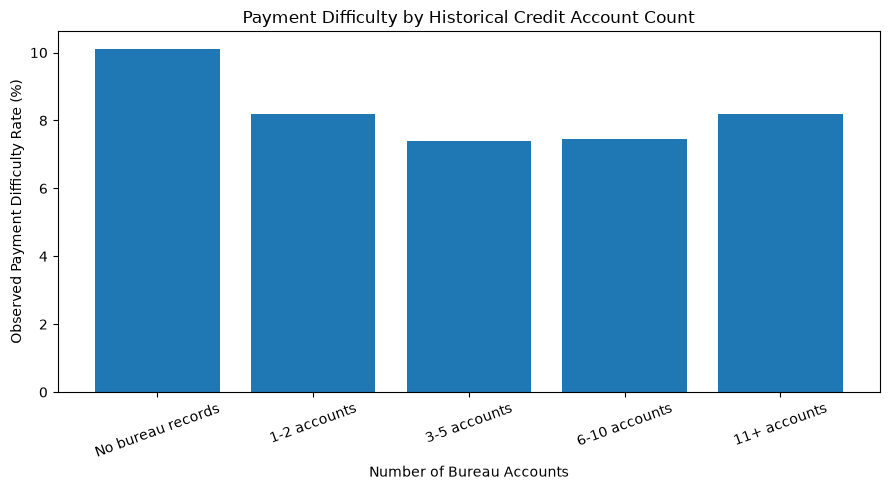

In [13]:
order = [
    "No bureau records",
    "1-2 accounts",
    "3-5 accounts",
    "6-10 accounts",
    "11+ accounts"
]

account_risk["account_group"] = pd.Categorical(
    account_risk["account_group"],
    categories=order,
    ordered=True
)

account_risk = account_risk.sort_values("account_group")

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    account_risk["account_group"].astype(str),
    account_risk["difficulty_rate_pct"]
)

ax.set_title(
    "Payment Difficulty by Historical Credit Account Count"
)
ax.set_xlabel("Number of Bureau Accounts")
ax.set_ylabel("Observed Payment Difficulty Rate (%)")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [14]:
OUTPUT_PATH = OUTPUT_DIR / "modeling_features.parquet"

con.execute(f"""
    COPY (
        SELECT *
        FROM modeling_features
    )
    TO {sql_path(OUTPUT_PATH)}
    (FORMAT PARQUET);
""")

print(f"Saved processed dataset to: {OUTPUT_PATH}")

Saved processed dataset to: /Users/preeyapat/Desktop/Project-HomeCreditDefaultRisk/data/processed/modeling_features.parquet
